In [1]:
# 03 RFM Customer Segmentation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

pd.set_option('display.max_columns', None)

In [2]:
password = getpass("retail_user password: ")

url = URL.create(
    drivername="mysql+pymysql",
    username="retail_user",
    password=password,
    host="localhost",
    port=3306,
    database="retail_analysis"
)
engine = create_engine(url)

with engine.connect() as conn:
    print("Connected successfully")

retail_user password:  ········


Connected successfully


In [3]:
customers = pd.read_sql("SELECT * FROM v_customer_summary", engine)
print(customers.shape)
customers.head()

(4333, 7)


,customer_id,country,orders,total_spent,first_order,last_order,avg_order_value
0,12347,Iceland,7,4310.00,2010-12-07,2011-12-07,615.71
1,12348,Finland,4,1437.24,2010-12-16,2011-09-25,359.31
2,12349,Italy,1,1457.55,2011-11-21,2011-11-21,1457.55
3,12350,Norway,1,294.40,2011-02-02,2011-02-02,294.40
4,12352,Norway,7,1385.74,2011-02-16,2011-11-03,197.96


In [4]:
customers['first_order'] = pd.to_datetime(customers['first_order'])
customers['last_order']  = pd.to_datetime(customers['last_order'])
customers['total_spent'] = customers['total_spent'].astype(float)
customers.dtypes

customer_id                int64
country                      str
orders                     int64
total_spent              float64
first_order        datetime64[s]
last_order         datetime64[s]
avg_order_value          float64
dtype: object

In [5]:
snapshot_date = customers['last_order'].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

Snapshot date: 2011-12-10 00:00:00


In [6]:
rfm = pd.DataFrame({
    'customer_id': customers['customer_id'],
    'country':     customers['country'],
    'recency':     (snapshot_date - customers['last_order']).dt.days,
    'frequency':   customers['orders'],
    'monetary':    customers['total_spent']
})
rfm.head()

,customer_id,country,recency,frequency,monetary
0,12347,Iceland,3,7,4310.00
1,12348,Finland,76,4,1437.24
2,12349,Italy,19,1,1457.55
3,12350,Norway,311,1,294.40
4,12352,Norway,37,7,1385.74


In [7]:
print("Rows:", len(rfm))
print("Unique customers:", rfm['customer_id'].is_unique)
print("Total monetary:", round(rfm['monetary'].sum(), 2))
rfm[['recency', 'frequency', 'monetary']].describe()

Rows: 4333
Unique customers: True
Total monetary: 8491574.44


,recency,frequency,monetary
count,4333.000000,4333.000000,4333.000000
mean,93.220171,4.246480,1959.744851
std,100.129302,7.635794,8461.153789
min,1.000000,1.000000,2.900000
25%,18.000000,1.000000,303.970000
50%,51.000000,2.000000,661.320000
75%,143.000000,5.000000,1628.560000
max,374.000000,206.000000,279138.020000


In [8]:
rfm['frequency'].value_counts().sort_index().head(12)

frequency
1     1505
2      830
3      502
4      395
5      236
6      173
7      139
8       98
9       69
10      54
11      54
12      43
Name: count, dtype: int64

In [9]:
rfm['r_score'] = pd.qcut(rfm['recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)

In [10]:
rfm['m_score'] = pd.qcut(rfm['monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [11]:
rfm['f_score'] = pd.cut(rfm['frequency'],
                        bins=[0, 1, 2, 4, 8, np.inf],
                        labels=[1, 2, 3, 4, 5]).astype(int)

In [12]:
for col in ['r_score', 'f_score', 'm_score']:
    print(col)
    print(rfm[col].value_counts().sort_index())
    print()

r_score
r_score
1    863
2    861
3    865
4    840
5    904
Name: count, dtype: int64

f_score
f_score
1    1505
2     830
3     897
4     646
5     455
Name: count, dtype: int64

m_score
m_score
1    867
2    866
3    867
4    866
5    867
Name: count, dtype: int64



In [13]:
rfm.groupby('r_score')['recency'].agg(['min', 'max', 'count'])

,min,max,count
r_score,,,
1,181,374,863
2,73,180,861
3,34,72,865
4,16,33,840
5,1,15,904


In [14]:
conditions = [
    (rfm['r_score'] >= 4) & (rfm['f_score'] >= 4) & (rfm['m_score'] >= 4),  # Champions
    (rfm['r_score'] >= 3) & (rfm['f_score'] >= 3),                          # Loyal Customers
    (rfm['r_score'] >= 4) & (rfm['f_score'] == 1),                          # New Customers
    (rfm['r_score'] >= 4) & (rfm['f_score'] == 2),                          # Potential Loyalists
    (rfm['r_score'] <= 2) & (rfm['f_score'] >= 3),                          # At Risk
    (rfm['r_score'] <= 2) & (rfm['f_score'] <= 2),                          # Lost
]

labels = ['Champions', 'Loyal Customers', 'New Customers',
          'Potential Loyalists', 'At Risk', 'Lost']

rfm['segment'] = np.select(conditions, labels, default='Needs Attention')

In [15]:
print(rfm['segment'].isnull().sum())          # should be 0
print(rfm['segment'].value_counts())
print(rfm['segment'].value_counts().sum())    # should be 4334

0
segment
Lost                   1340
Loyal Customers         834
Champions               780
Needs Attention         478
At Risk                 384
Potential Loyalists     279
New Customers           238
Name: count, dtype: int64
4333


In [16]:
summary = (rfm.groupby('segment')
           .agg(customers=('customer_id', 'count'),
                revenue=('monetary', 'sum'),
                avg_recency_days=('recency', 'mean'),
                avg_orders=('frequency', 'mean'),
                avg_spend=('monetary', 'mean'))
           .reset_index())

summary['pct_customers'] = 100 * summary['customers'] / summary['customers'].sum()
summary['pct_revenue']   = 100 * summary['revenue'] / summary['revenue'].sum()

summary = summary.round(2).sort_values('revenue', ascending=False).reset_index(drop=True)
summary

,segment,customers,revenue,avg_recency_days,avg_orders,avg_spend,pct_customers,pct_revenue
0,Champions,780,5354019.59,12.47,12.67,6864.13,18.00,63.05
1,Loyal Customers,834,1397676.31,32.17,4.42,1675.87,19.25,16.46
2,At Risk,384,638035.26,136.03,4.35,1661.55,8.86,7.51
3,Lost,1340,600858.12,209.35,1.28,448.40,30.93,7.08
4,Needs Attention,478,248817.02,53.10,1.37,520.54,11.03,2.93
5,Potential Loyalists,279,176521.30,16.50,2.00,632.69,6.44,2.08
6,New Customers,238,75646.84,19.40,1.00,317.84,5.49,0.89


In [17]:
print(summary['customers'].sum(), round(summary['revenue'].sum(), 2))

4333 8491574.44


In [18]:
rfm.to_csv('../data/cleaned/rfm_segments.csv', index=False)
summary.to_csv('../data/cleaned/rfm_segment_summary.csv', index=False)


In [19]:
segment_order = ['Champions', 'Loyal Customers', 'Potential Loyalists',
                 'New Customers', 'Needs Attention', 'At Risk', 'Lost']

summary_plot = summary.set_index('segment').loc[segment_order].reset_index()
summary_plot[['segment', 'customers', 'pct_customers', 'pct_revenue']]

,segment,customers,pct_customers,pct_revenue
0,Champions,780,18.00,63.05
1,Loyal Customers,834,19.25,16.46
2,Potential Loyalists,279,6.44,2.08
3,New Customers,238,5.49,0.89
4,Needs Attention,478,11.03,2.93
5,At Risk,384,8.86,7.51
6,Lost,1340,30.93,7.08


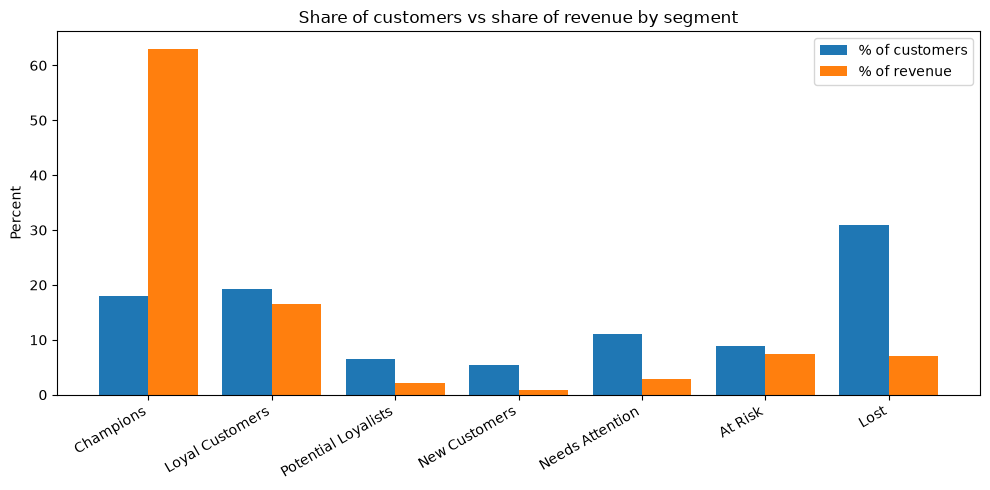

In [20]:
x = np.arange(len(summary_plot))
width = 0.4

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width/2, summary_plot['pct_customers'], width, label='% of customers')
ax.bar(x + width/2, summary_plot['pct_revenue'],   width, label='% of revenue')

ax.set_xticks(x)
ax.set_xticklabels(summary_plot['segment'], rotation=30, ha='right')
ax.set_ylabel('Percent')
ax.set_title('Share of customers vs share of revenue by segment')
ax.legend()

plt.tight_layout()
plt.savefig('../reports/segment_customers_vs_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

**Chart 1:** Champions make up 18% of customers but generate about 61% of revenue, while Lost customers are 31% of the customer base but only about 8% of revenue. Retention efforts should focus on the top segments.

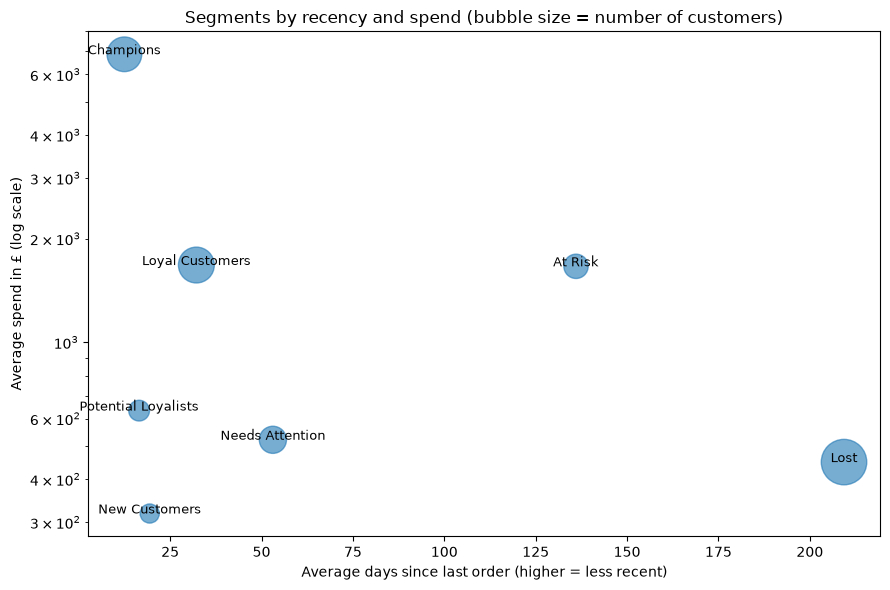

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(summary['avg_recency_days'], summary['avg_spend'],
           s=summary['customers'] * 0.8, alpha=0.6)

for _, row in summary.iterrows():
    ax.annotate(row['segment'], (row['avg_recency_days'], row['avg_spend']),
                ha='center', fontsize=9)

ax.set_yscale('log')
ax.set_xlabel('Average days since last order (higher = less recent)')
ax.set_ylabel('Average spend in £ (log scale)')
ax.set_title('Segments by recency and spend (bubble size = number of customers)')

plt.tight_layout()
plt.savefig('../reports/segment_recency_vs_spend.png', dpi=150, bbox_inches='tight')
plt.show()

**Chart 2:** At Risk customers spend about the same as Loyal customers (about £1,660) but have been inactive for 136 days on average, against 32 days for Loyal customers. They are valuable customers who have gone quiet.

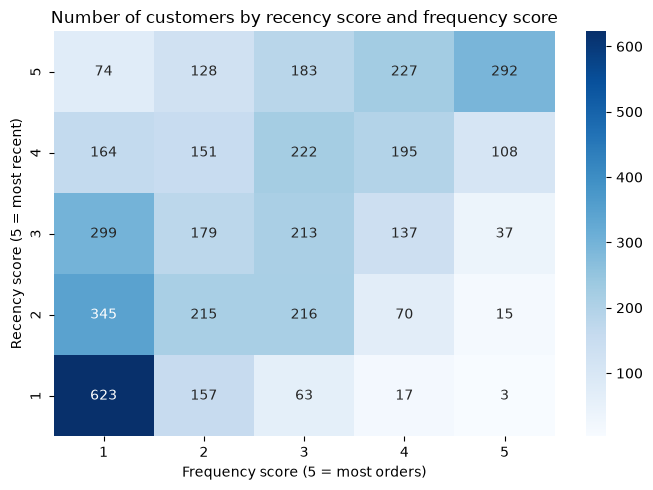

In [22]:
heat = (rfm.pivot_table(index='r_score', columns='f_score',
                        values='customer_id', aggfunc='count')
           .fillna(0).astype(int)
           .sort_index(ascending=False))

plt.figure(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt='d', cmap='Blues')
plt.title('Number of customers by recency score and frequency score')
plt.xlabel('Frequency score (5 = most orders)')
plt.ylabel('Recency score (5 = most recent)')

plt.tight_layout()
plt.savefig('../reports/rfm_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Chart 3:** (write what you see in the heatmap, for example where most customers cluster)

In [23]:
rfm.to_sql('rfm_segments', engine, if_exists='replace', index=False)
summary.to_sql('rfm_segment_summary', engine, if_exists='replace', index=False)
print("Saved to MySQL")

Saved to MySQL


## Segment findings and recommendations

| Segment | Customers | % of revenue | Recommended action |
|---|---|---|---|
| Champions | 780 | 61.3% | Reward and retain: early access to new products, loyalty perks, ask for referrals. Losing even a few of these customers hurts revenue most |
| Loyal Customers | 834 | 16.0% | Upsell and cross-sell, introduce a loyalty programme to move them towards Champions |
| Potential Loyalists | 280 | 3.9% | Encourage a third order with a bundle or a time-limited offer |
| New Customers | 238 | 0.9% | Welcome email and a second-purchase incentive, since the first repeat order is the key step |
| Needs Attention | 478 | 2.8% | Reminder email with popular products, a low-cost nudge |
| At Risk | 384 | 7.3% | Priority win-back campaign: personal outreach or a discount. Their spend is similar to Loyal customers, but they have been silent for about 136 days |
| Lost | 1,340 | 7.8% | Low-cost reactivation (a single email). Do not spend heavily here |

### Key insights
- Champions and Loyal Customers together are about 37% of customers but about 77% of revenue.
- At Risk customers behave like Loyal customers except for recency, so they are the best win-back target (about £638k of revenue).
- Lost is the largest group by headcount (31%) but contributes only about 8% of revenue.

### Limitations
- The data covers only 12 months, so "Lost" means inactive within this window, not necessarily gone for good.
- About 15% of revenue has no customer ID and is excluded from RFM.
- A few very large wholesale accounts pull the average spend in Champions up.